# 01 - Exploratory Data Analysis
London Fire Brigade response-time prediction (target: `Response`, seconds).

Rule: the test set has no target and is **never used for fitting or tuning**. Here it is only used for
data-quality checks and a train-vs-test feature distribution comparison.

## 0. Setup

In [8]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Plot style and reproducibility
sns.set_theme(style="whitegrid")
RANDOM_SEED = 42

# Paths (notebook lives in notebooks/, so go one level up to reach the project root)
PROJECT_ROOT = Path("..").resolve()
TRAIN_PATH = PROJECT_ROOT / "data" / "raw" / "fire_response_train.csv"
TEST_PATH = PROJECT_ROOT / "data" / "raw" / "fire_response_test.csv"
BOROUGH_GEOJSON_PATH = PROJECT_ROOT / "data" / "external" / "london_boroughs.geojson"
FIGURE_DIR = PROJECT_ROOT / "output" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(name):
    # Save the current matplotlib figure into output/figures/
    plt.savefig(FIGURE_DIR / f"eda_{name}.png", dpi=150, bbox_inches="tight")

In [9]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Plot style and reproducibility
sns.set_theme(style="whitegrid")
RANDOM_SEED = 42

# Paths (notebook lives in notebooks/, so go one level up to reach the project root)
PROJECT_ROOT = Path("..").resolve()
TRAIN_PATH = PROJECT_ROOT / "data" / "raw" / "fire_response_train.csv"
TEST_PATH = PROJECT_ROOT / "data" / "raw" / "fire_response_test.csv"
BOROUGH_GEOJSON_PATH = PROJECT_ROOT / "data" / "external" / "london_boroughs.geojson"
FIGURE_DIR = PROJECT_ROOT / "output" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(name):
    # Save the current matplotlib figure into output/figures/
    plt.savefig(FIGURE_DIR / f"eda_{name}.png", dpi=150, bbox_inches="tight")

## 1. Load data and basic structure

In [10]:
# Load both files
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

TARGET = "Response"
feature_columns = [column for column in train.columns if column != TARGET]

print(f"Train: {train.shape[0]} rows, {train.shape[1]} columns (incl. target)")
print(f"Test : {test.shape[0]} rows, {test.shape[1]} columns")
print(f"Number of features: {len(feature_columns)}")
print("Train/test have same feature columns in the same order:", feature_columns == list(test.columns))

Train: 24000 rows, 19 columns (incl. target)
Test : 6000 rows, 18 columns
Number of features: 18
Train/test have same feature columns in the same order: True


In [11]:
# First rows and data types
display(train.head())
display(train.dtypes.to_frame("dtype").T)

,call_year,easting_km,northing_km,prior_incidents_city_15min,prior_incidents_city_60min,prior_incidents_city_6h,prior_incidents_city_24h,prior_incidents_station_60min,prior_incidents_station_6h,prior_incidents_station_24h,prior_incidents_borough_60min,prior_incidents_borough_24h,call_month,call_weekday,call_hour,borough,postcode_district,station_ground,Response
0,2018,518.7584,167.2601,0,5,52,233,0,0,1,0,2,1,Tuesday,2,KINGSTON UPON THAMES,KT5,SURBITON,231.51
1,2018,531.4653,184.5515,1,8,38,207,0,1,6,0,13,1,Tuesday,10,ISLINGTON,N1,ISLINGTON,126.00
2,2018,528.7476,165.4467,3,10,52,204,1,2,2,1,5,1,Tuesday,14,SUTTON,SM6,WALLINGTON,233.24
3,2018,532.2296,175.3468,1,15,63,210,1,2,4,2,11,1,Tuesday,15,LAMBETH,SE24,BRIXTON,315.04
4,2018,531.4362,175.5571,5,12,73,206,1,4,7,1,12,1,Tuesday,19,LAMBETH,SW9,BRIXTON,9.58


,call_year,easting_km,northing_km,prior_incidents_city_15min,prior_incidents_city_60min,prior_incidents_city_6h,prior_incidents_city_24h,prior_incidents_station_60min,prior_incidents_station_6h,prior_incidents_station_24h,prior_incidents_borough_60min,prior_incidents_borough_24h,call_month,call_weekday,call_hour,borough,postcode_district,station_ground,Response
dtype,int64,float64,float64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,str,int64,str,str,str,float64


In [12]:
# Split features into numeric and categorical (string) columns
categorical_columns = train[feature_columns].select_dtypes(include=["object", "string"]).columns.tolist()
numeric_columns = [column for column in feature_columns if column not in categorical_columns]
print("Categorical:", categorical_columns)
print("Numeric    :", numeric_columns)

Categorical: ['call_weekday', 'borough', 'postcode_district', 'station_ground']
Numeric    : ['call_year', 'easting_km', 'northing_km', 'prior_incidents_city_15min', 'prior_incidents_city_60min', 'prior_incidents_city_6h', 'prior_incidents_city_24h', 'prior_incidents_station_60min', 'prior_incidents_station_6h', 'prior_incidents_station_24h', 'prior_incidents_borough_60min', 'prior_incidents_borough_24h', 'call_month', 'call_hour']


## 2. Data quality

In [13]:
# Missing values per column, train and test side by side
missing_overview = pd.DataFrame({
    "train_missing": train.isna().sum(),
    "test_missing": test.isna().sum().reindex(train.columns),
})
display(missing_overview[(missing_overview > 0).any(axis=1)] if missing_overview.any().any() else "No missing values in train or test.")

'No missing values in train or test.'

In [14]:
# Duplicate rows and constant columns
print("Duplicate rows in train:", train.duplicated().sum())
print("Duplicate rows in test :", test.duplicated().sum())
constant_columns = [column for column in train.columns if train[column].nunique() == 1]
print("Constant columns:", constant_columns)

Duplicate rows in train: 0
Duplicate rows in test : 0
Constant columns: []


In [15]:
# Sanity checks for impossible values
count_columns = [column for column in numeric_columns if column.startswith("prior_incidents")]
print("Negative counts in prior_incidents_*:", int((train[count_columns] < 0).sum().sum()))
print("call_hour outside 0-23:", int((~train["call_hour"].between(0, 23)).sum()))
print("call_month outside 1-12:", int((~train["call_month"].between(1, 12)).sum()))
print("Non-positive Response:", int((train[TARGET] <= 0).sum()))
display(train[["easting_km", "northing_km"]].describe().T)

# Consistency: a longer window can never contain fewer incidents than a shorter one
nested_checks = {
    "city: 15min <= 60min": (train["prior_incidents_city_15min"] <= train["prior_incidents_city_60min"]).all(),
    "city: 60min <= 6h": (train["prior_incidents_city_60min"] <= train["prior_incidents_city_6h"]).all(),
    "city: 6h <= 24h": (train["prior_incidents_city_6h"] <= train["prior_incidents_city_24h"]).all(),
    "station: 60min <= 6h": (train["prior_incidents_station_60min"] <= train["prior_incidents_station_6h"]).all(),
    "station: 6h <= 24h": (train["prior_incidents_station_6h"] <= train["prior_incidents_station_24h"]).all(),
    "borough: 60min <= 24h": (train["prior_incidents_borough_60min"] <= train["prior_incidents_borough_24h"]).all(),
}
print(nested_checks)

Negative counts in prior_incidents_*: 0
call_hour outside 0-23: 0
call_month outside 1-12: 0
Non-positive Response: 4


,count,mean,std,min,25%,50%,75%,max
easting_km,24000.0,530.600354,9.706551,504.2528,525.064450,530.85460,536.259725,559.2522
northing_km,24000.0,180.480069,7.423525,157.1500,176.048475,181.04775,185.258000,200.6555


{'city: 15min <= 60min': np.True_, 'city: 60min <= 6h': np.True_, 'city: 6h <= 24h': np.True_, 'station: 60min <= 6h': np.True_, 'station: 6h <= 24h': np.True_, 'borough: 60min <= 24h': np.True_}


## 3. Target analysis

In [16]:
# Summary statistics, skewness and tail quantiles
print(train[TARGET].describe())
print("Skewness:", round(train[TARGET].skew(), 3))
print("Kurtosis:", round(train[TARGET].kurt(), 3))
print(train[TARGET].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]))

count    24000.00000
mean       311.56250
std        133.13692
min          0.00000
25%        228.41750
50%        292.66500
75%        371.49250
max       1203.16000
Name: Response, dtype: float64
Skewness: 1.433
Kurtosis: 4.896
0.010      29.55960
0.050     142.00550
0.250     228.41750
0.500     292.66500
0.750     371.49250
0.950     544.78100
0.990     777.43480
0.999    1103.10036
Name: Response, dtype: float64


/home/songshu/Projects/IntroML/.venv/lib/python3.14/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


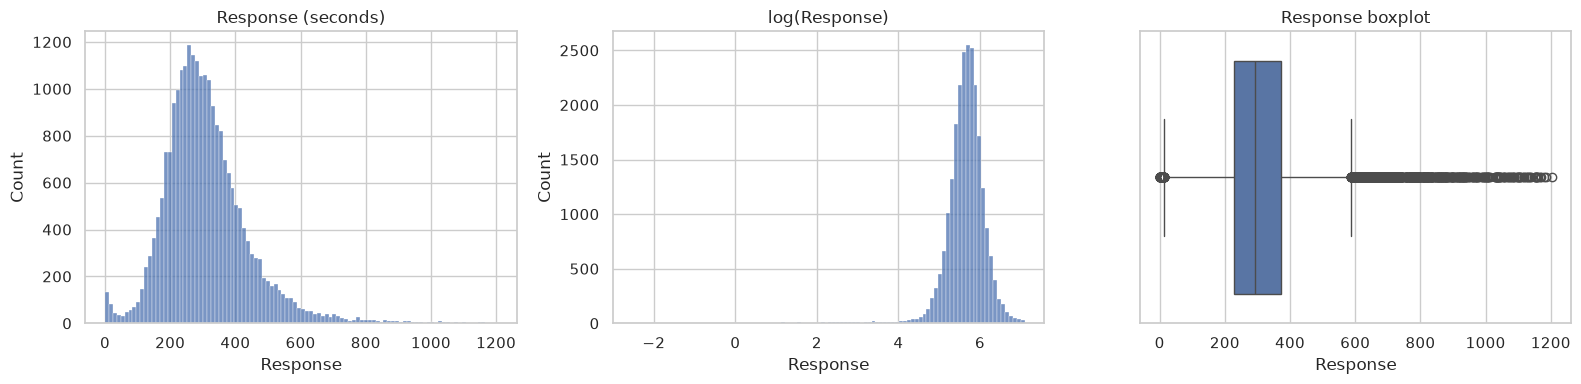

In [17]:
# Distribution: raw, log-scale, and boxplot
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(train[TARGET], bins=100, ax=axes[0])
axes[0].set_title("Response (seconds)")
sns.histplot(np.log(train[TARGET]), bins=100, ax=axes[1])
axes[1].set_title("log(Response)")
sns.boxplot(x=train[TARGET], ax=axes[2])
axes[2].set_title("Response boxplot")
plt.tight_layout()
save_figure("target_distribution")
plt.show()

In [18]:
# How much of the total squared deviation comes from the extreme tail?
# MSE is dominated by large values, so this tells us how much outliers matter.
squared_deviation = (train[TARGET] - train[TARGET].mean()) ** 2
sorted_deviation = squared_deviation.sort_values(ascending=False)
for top_fraction in [0.001, 0.01, 0.05]:
    top_count = int(len(train) * top_fraction)
    share = sorted_deviation.iloc[:top_count].sum() / squared_deviation.sum()
    print(f"Top {top_fraction:.1%} of observations ({top_count} rows) carry {share:.1%} of total squared deviation")
display(train.nlargest(10, TARGET))

Top 0.1% of observations (24 rows) carry 3.9% of total squared deviation
Top 1.0% of observations (240 rows) carry 21.7% of total squared deviation
Top 5.0% of observations (1200 rows) carry 46.2% of total squared deviation


,call_year,easting_km,northing_km,prior_incidents_city_15min,prior_incidents_city_60min,prior_incidents_city_6h,prior_incidents_city_24h,prior_incidents_station_60min,prior_incidents_station_6h,prior_incidents_station_24h,prior_incidents_borough_60min,prior_incidents_borough_24h,call_month,call_weekday,call_hour,borough,postcode_district,station_ground,Response
21720,2022,537.8746,179.1632,15,38,137,572,0,1,3,2,28,7,Tuesday,12,TOWER HAMLETS,E14,MILLWALL,1203.16
10137,2020,528.4395,176.4457,1,7,74,276,0,0,0,0,8,2,Monday,0,WANDSWORTH,SW11,BATTERSEA,1183.99
5869,2019,518.3505,182.1392,2,12,82,283,0,2,2,2,7,4,Tuesday,22,EALING,W5,EALING,1178.66
17208,2021,507.3528,178.9493,8,23,89,269,0,0,0,0,10,9,Friday,14,HILLINGDON,UB7,HAYES,1169.78
2237,2018,535.7441,200.0452,0,8,44,331,0,1,6,0,11,7,Monday,7,ENFIELD,EN8,ENFIELD,1165.48
8469,2019,547.2387,168.7571,7,19,107,311,0,0,1,0,5,10,Sunday,17,BROMLEY,BR5,ORPINGTON,1162.17
7446,2019,547.9397,168.3369,4,14,91,294,0,0,0,1,7,8,Thursday,16,BROMLEY,BR5,ORPINGTON,1158.21
1949,2018,530.9609,192.0527,1,3,17,308,0,0,2,0,13,6,Tuesday,6,ENFIELD,N13,SOUTHGATE,1158.19
655,2018,532.3455,181.4468,6,23,146,427,0,2,10,0,8,3,Thursday,19,CITY OF LONDON,EC2P,DOWGATE,1154.93
2662,2018,525.2590,191.8460,10,26,127,418,0,1,3,1,17,7,Thursday,17,BARNET,N3,FINCHLEY,1154.28


## 4. Numeric features

In [19]:
# Summary statistics of numeric features, plus share of zeros and skewness
numeric_summary = train[numeric_columns].describe().T
numeric_summary["share_zero"] = (train[numeric_columns] == 0).mean()
numeric_summary["skew"] = train[numeric_columns].skew()
display(numeric_summary.round(3))

,count,mean,std,min,25%,50%,75%,max,share_zero,skew
call_year,24000.0,2020.042,1.432,2018.000,2019.000,2020.000,2021.000,2022.000,0.000,-0.038
easting_km,24000.0,530.600,9.707,504.253,525.064,530.855,536.260,559.252,0.000,-0.082
northing_km,24000.0,180.480,7.424,157.150,176.048,181.048,185.258,200.656,0.000,-0.242
prior_incidents_city_15min,24000.0,3.687,2.734,0.000,2.000,3.000,5.000,63.000,0.056,4.661
prior_incidents_city_60min,24000.0,14.672,8.262,0.000,10.000,14.000,18.000,219.000,0.001,7.680
prior_incidents_city_6h,24000.0,82.734,35.727,12.000,60.000,84.000,100.000,768.000,0.000,4.631
prior_incidents_city_24h,24000.0,304.679,65.220,164.000,267.000,295.000,330.000,1209.000,0.000,3.967
prior_incidents_station_60min,24000.0,0.212,0.793,0.000,0.000,0.000,0.000,57.000,0.827,35.352
prior_incidents_station_6h,24000.0,1.051,1.685,0.000,0.000,1.000,2.000,110.000,0.421,23.268
prior_incidents_station_24h,24000.0,3.737,3.522,0.000,2.000,3.000,5.000,231.000,0.069,15.639


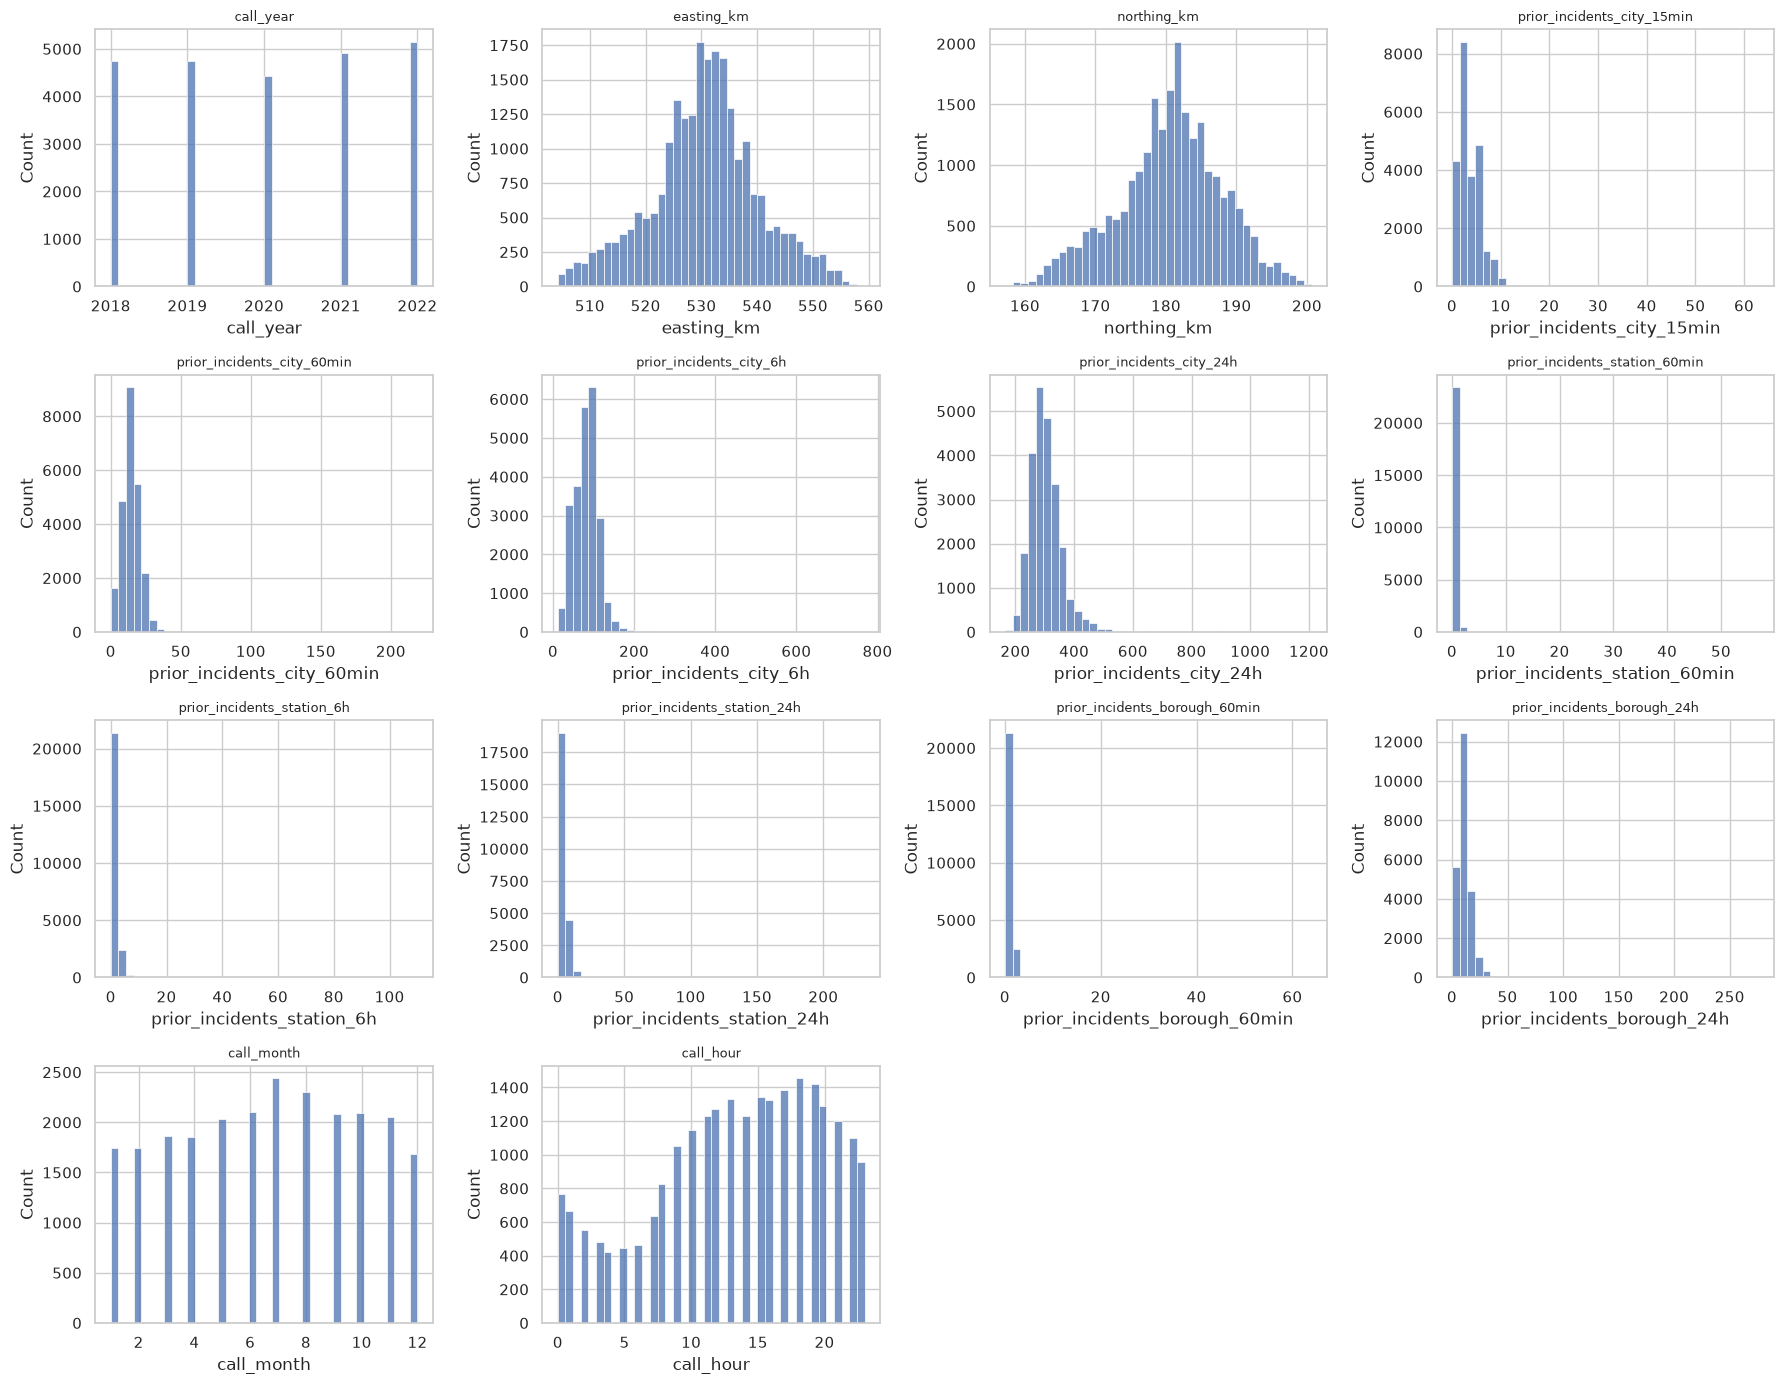

In [20]:
# Histograms of all numeric features
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for axis, column in zip(axes.ravel(), numeric_columns):
    sns.histplot(train[column], bins=40, ax=axis)
    axis.set_title(column, fontsize=9)
for axis in axes.ravel()[len(numeric_columns):]:
    axis.set_visible(False)
plt.tight_layout()
save_figure("numeric_histograms")
plt.show()

## 5. Categorical features

In [21]:
# Cardinality, and levels that appear in test but not in train (unseen levels break naive encoders)
for column in categorical_columns:
    train_levels = set(train[column])
    test_levels = set(test[column])
    unseen_in_train = test_levels - train_levels
    rows_affected = test[column].isin(unseen_in_train).sum()
    print(f"{column:18s} levels in train: {len(train_levels):4d} | in test: {len(test_levels):4d} | "
          f"unseen in train: {len(unseen_in_train)} ({rows_affected} test rows)")

call_weekday       levels in train:    7 | in test:    7 | unseen in train: 0 (0 test rows)
borough            levels in train:   33 | in test:   33 | unseen in train: 0 (0 test rows)
postcode_district  levels in train:  292 | in test:  277 | unseen in train: 0 (0 test rows)
station_ground     levels in train:  102 | in test:  102 | unseen in train: 0 (0 test rows)


borough: min=251, median=721.0, max=1794, levels with <30 rows: 0
postcode_district: min=1, median=66.0, max=503, levels with <30 rows: 67
station_ground: min=32, median=215.5, max=815, levels with <30 rows: 0


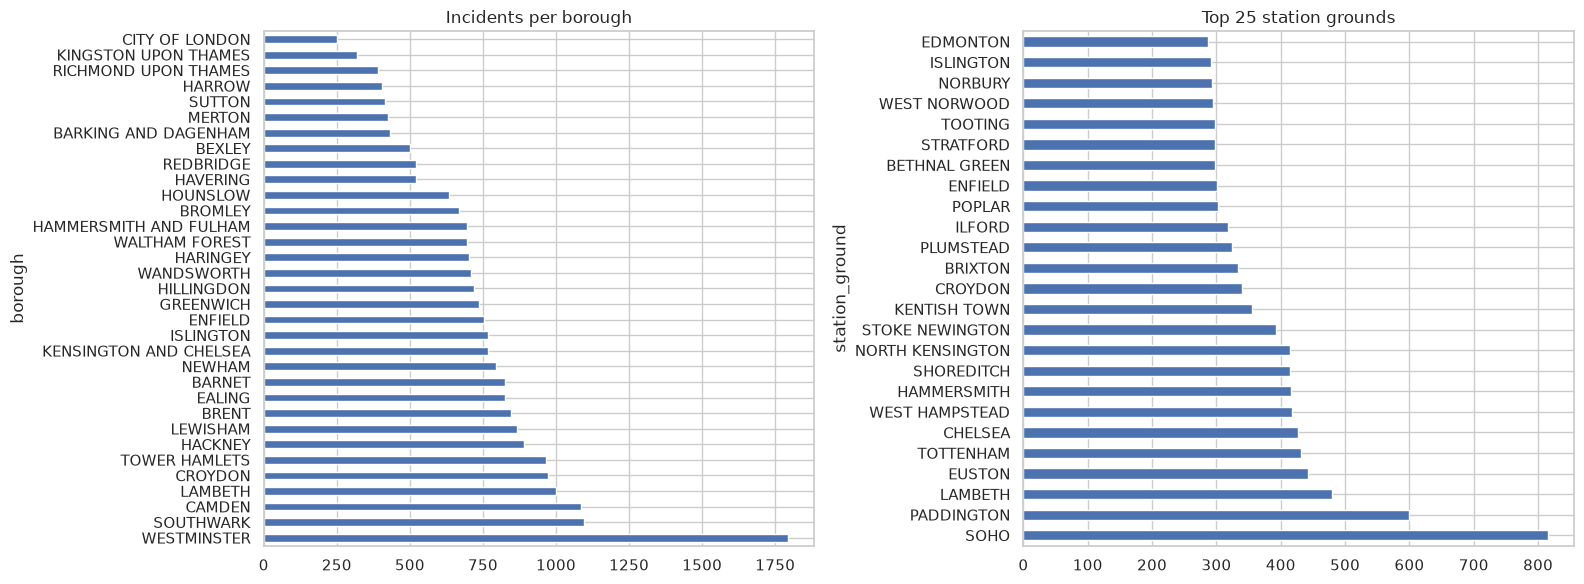

In [22]:
# Level frequency: how many levels are rare (< 30 rows)? Matters for one-hot / target encoding
for column in ["borough", "postcode_district", "station_ground"]:
    counts = train[column].value_counts()
    print(f"{column}: min={counts.min()}, median={counts.median()}, max={counts.max()}, levels with <30 rows: {(counts < 30).sum()}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
train["borough"].value_counts().plot.barh(ax=axes[0], title="Incidents per borough")
train["station_ground"].value_counts().head(25).plot.barh(ax=axes[1], title="Top 25 station grounds")
plt.tight_layout()
save_figure("categorical_counts")
plt.show()

In [23]:
# Relationship between the three geography variables (station vs borough vs postcode)
print("Postcodes spanning >1 borough:", int((train.groupby("postcode_district")["borough"].nunique() > 1).sum()))
print("Station grounds spanning >1 borough:", int((train.groupby("station_ground")["borough"].nunique() > 1).sum()))

Postcodes spanning >1 borough: 130
Station grounds spanning >1 borough: 79


## 6. Target versus features

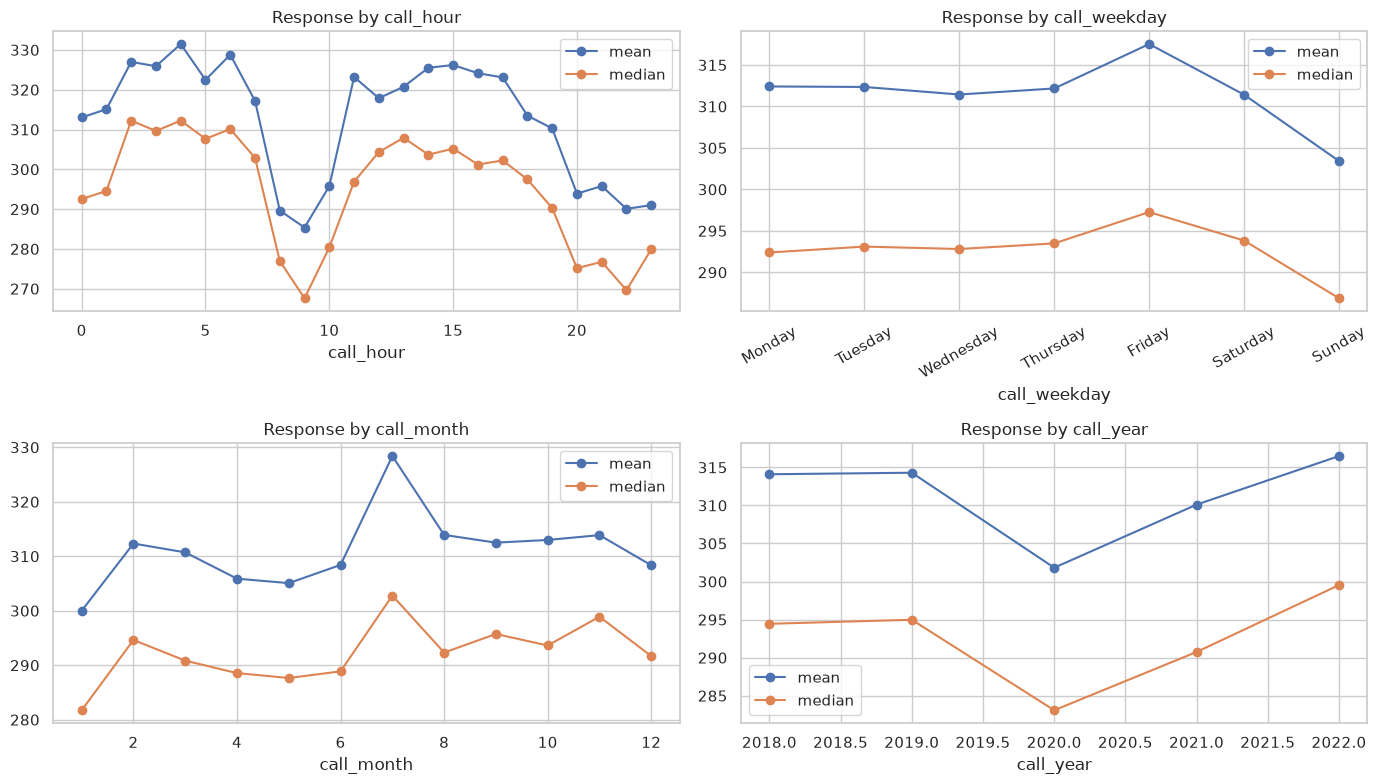

In [24]:
# Mean and median Response by calendar variables
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for axis, (column, order) in zip(axes.ravel(), [("call_hour", None), ("call_weekday", weekday_order),
                                                 ("call_month", None), ("call_year", None)]):
    grouped = train.groupby(column)[TARGET].agg(["mean", "median"])
    if order is not None:
        grouped = grouped.reindex(order)
    grouped.plot(ax=axis, marker="o", title=f"Response by {column}")
    if order is not None:
        axis.tick_params(axis="x", rotation=30)
plt.tight_layout()
save_figure("target_by_calendar")
plt.show()

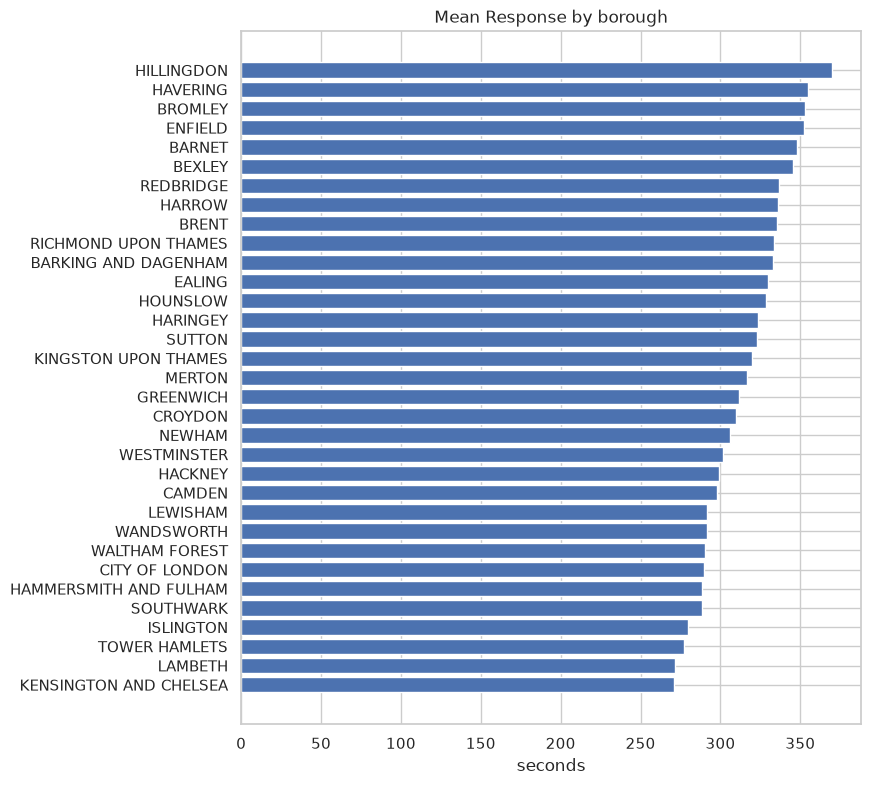

In [25]:
# Mean Response by borough
borough_means = train.groupby("borough")[TARGET].agg(["mean", "median", "count"]).sort_values("mean")
plt.figure(figsize=(8, 9))
plt.barh(borough_means.index, borough_means["mean"])
plt.title("Mean Response by borough")
plt.xlabel("seconds")
save_figure("target_by_borough")
plt.show()

### Spatial view: borough choropleth
Raw points (24k) overplot, so we aggregate per borough instead (train data only).
Boundaries: London borough GeoJSON from https://github.com/radoi90/housequest-data (saved in `data/external/`).

In [26]:
# Load borough polygons and reproject to British National Grid (metres), the CRS of easting/northing
boroughs_map = gpd.read_file(BOROUGH_GEOJSON_PATH).to_crs("EPSG:27700")
boroughs_map["borough"] = boroughs_map["name"].str.upper()   # data uses upper-case names

# Per-borough statistics of the target (train only)
borough_stats = train.groupby("borough")[TARGET].agg(["mean", "median", "std", "count"]).reset_index()

# Merge; assert every borough in the data matched exactly one polygon (no silent drops)
boroughs_map = boroughs_map.merge(borough_stats, on="borough", how="left", validate="one_to_one")
assert boroughs_map["mean"].notna().all(), "Some map polygons have no data"
assert set(train["borough"]) == set(boroughs_map["borough"]), "Borough names do not match"
print("Boroughs matched:", len(boroughs_map))

Boroughs matched: 33


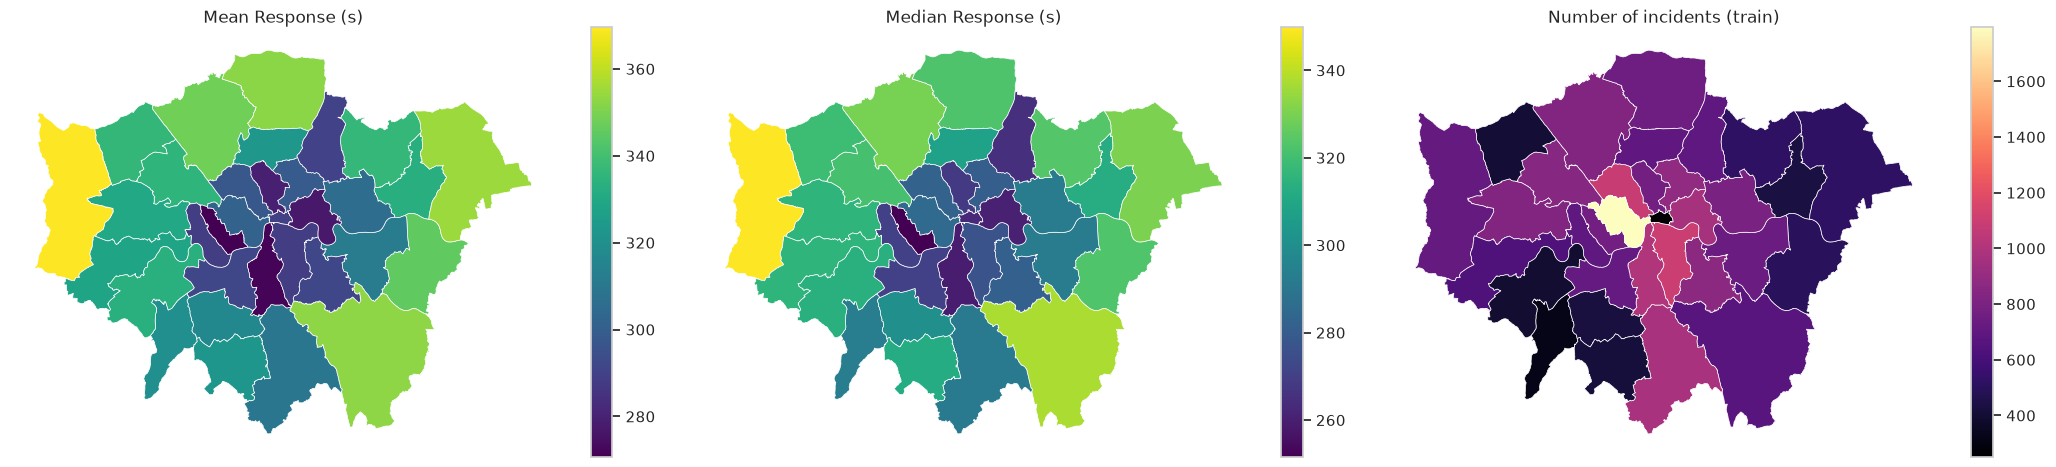

Std of borough means: 26.9 s
Mean within-borough std: 132.1 s


,borough,mean,median,std,count
19,KENSINGTON AND CHELSEA,270.7,251.6,116.4,768
21,LAMBETH,271.7,259.1,114.0,999
29,TOWER HAMLETS,277.0,260.7,116.8,967
4,BROMLEY,352.7,337.2,145.5,669
15,HAVERING,354.6,330.6,166.7,522
16,HILLINGDON,369.6,349.9,155.0,721


In [27]:
# Three panels: mean, median and incident count per borough
panels = [("mean", "Mean Response (s)", "viridis"),
          ("median", "Median Response (s)", "viridis"),
          ("count", "Number of incidents (train)", "magma")]
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for axis, (column, title, colormap) in zip(axes, panels):
    boroughs_map.plot(column=column, cmap=colormap, legend=True, edgecolor="white", linewidth=0.5,
                      legend_kwds={"shrink": 0.7}, ax=axis)
    axis.set_title(title)
    axis.set_axis_off()
plt.tight_layout()
save_figure("spatial_choropleth")
plt.show()

# Spread between boroughs vs spread within boroughs (tells us how much information borough carries)
print("Std of borough means:", round(borough_stats["mean"].std(), 1), "s")
print("Mean within-borough std:", round(borough_stats["std"].mean(), 1), "s")
display(borough_stats.sort_values("mean").iloc[[0, 1, 2, -3, -2, -1]].round(1))

In [28]:
# Sanity check: all incident coordinates fall inside the London boundary
points = gpd.GeoDataFrame(train, geometry=gpd.points_from_xy(train["easting_km"] * 1000, train["northing_km"] * 1000),
                          crs="EPSG:27700")
inside_london = points.within(boroughs_map.union_all())
print(f"Share of train incidents inside the borough polygons: {inside_london.mean():.2%}")

Share of train incidents inside the borough polygons: 99.96%


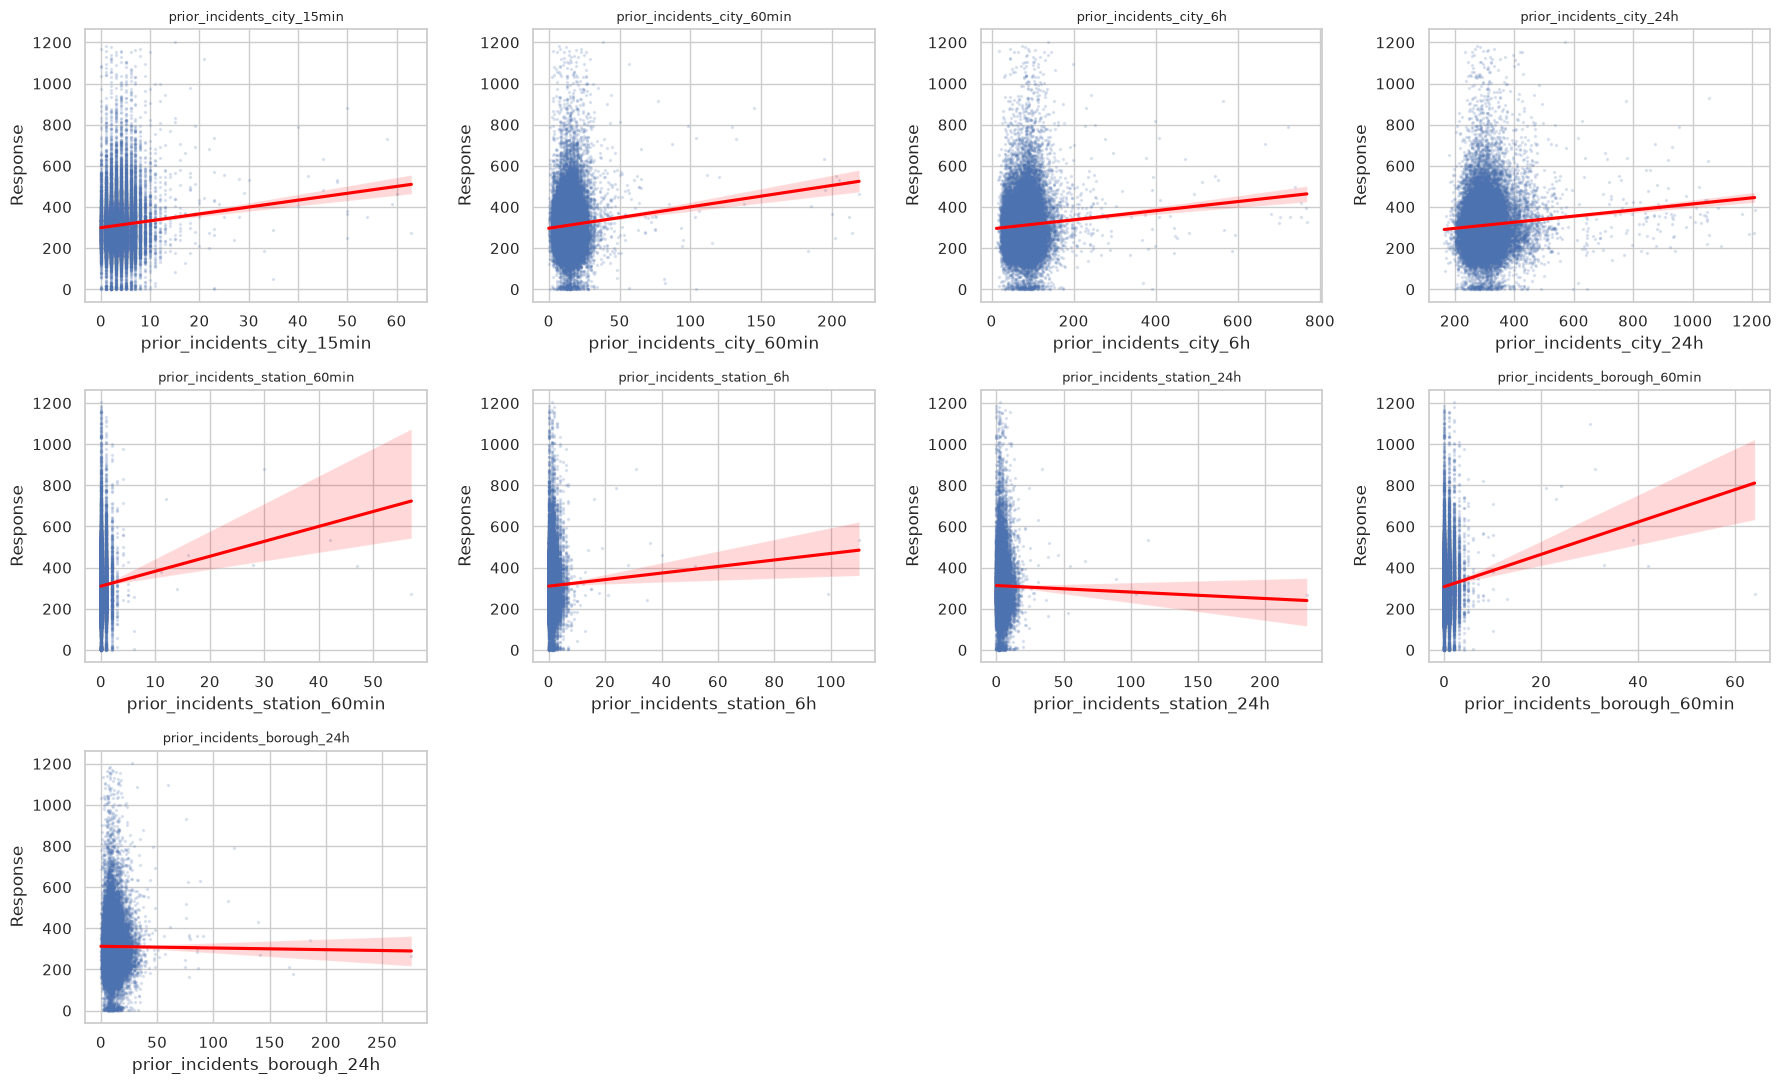

In [29]:
# Response against each numeric feature (binned means are clearer than raw scatter at 24k points)
scatter_columns = [column for column in numeric_columns if column.startswith("prior_incidents")]
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for axis, column in zip(axes.ravel(), scatter_columns):
    sns.regplot(x=train[column], y=train[TARGET], scatter_kws={"s": 2, "alpha": 0.15}, line_kws={"color": "red"},
                lowess=False, ax=axis)
    axis.set_title(column, fontsize=9)
for axis in axes.ravel()[len(scatter_columns):]:
    axis.set_visible(False)
plt.tight_layout()
save_figure("target_vs_prior_incidents")
plt.show()

## 7. Correlation and redundancy

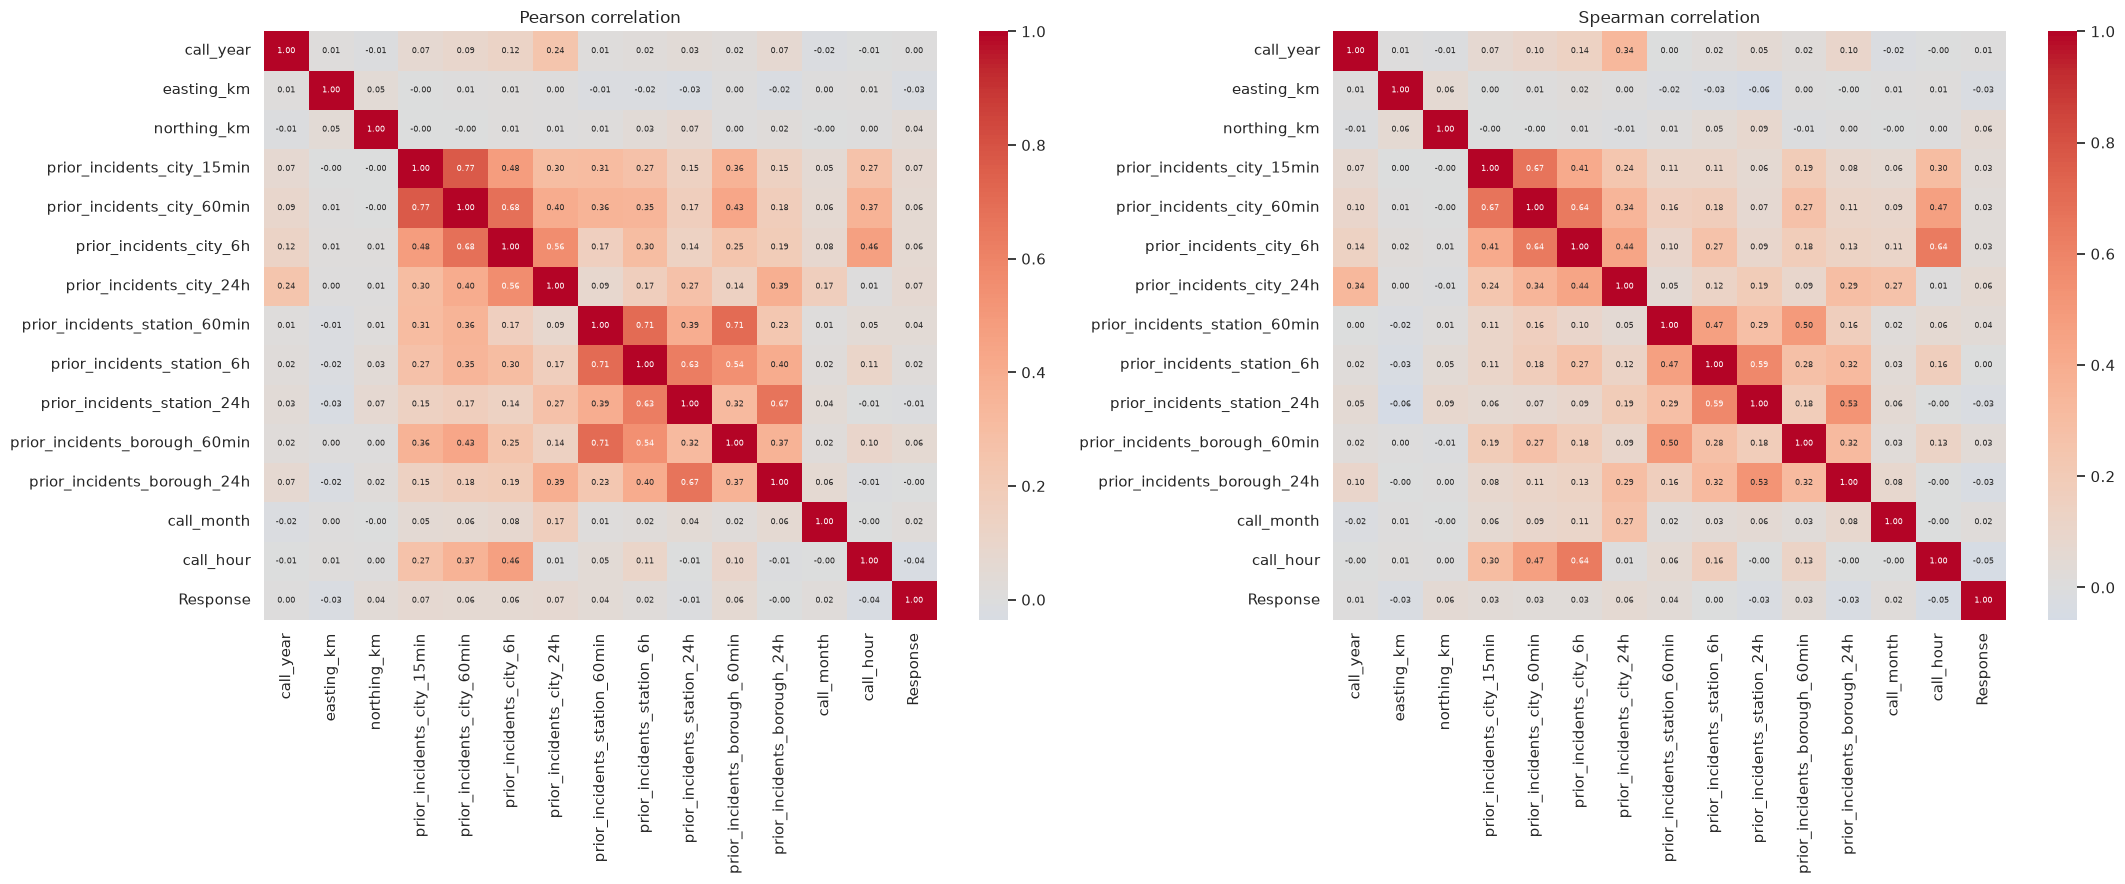

In [30]:
# Pearson and Spearman correlation heatmaps (numeric features + target)
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for axis, method in zip(axes, ["pearson", "spearman"]):
    correlation = train[numeric_columns + [TARGET]].corr(method=method)
    sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 6}, ax=axis)
    axis.set_title(f"{method.capitalize()} correlation")
plt.tight_layout()
save_figure("correlation_heatmaps")
plt.show()

In [31]:
# Highly correlated feature pairs (|r| > 0.8) -> multicollinearity, relevant for OLS vs ridge/lasso
correlation = train[numeric_columns].corr()
pairs = []
for i, first in enumerate(numeric_columns):
    for second in numeric_columns[i + 1:]:
        if abs(correlation.loc[first, second]) > 0.8:
            pairs.append((first, second, round(correlation.loc[first, second], 3)))
display(pd.DataFrame(pairs, columns=["feature_1", "feature_2", "pearson_r"]).sort_values("pearson_r", ascending=False))

,feature_1,feature_2,pearson_r


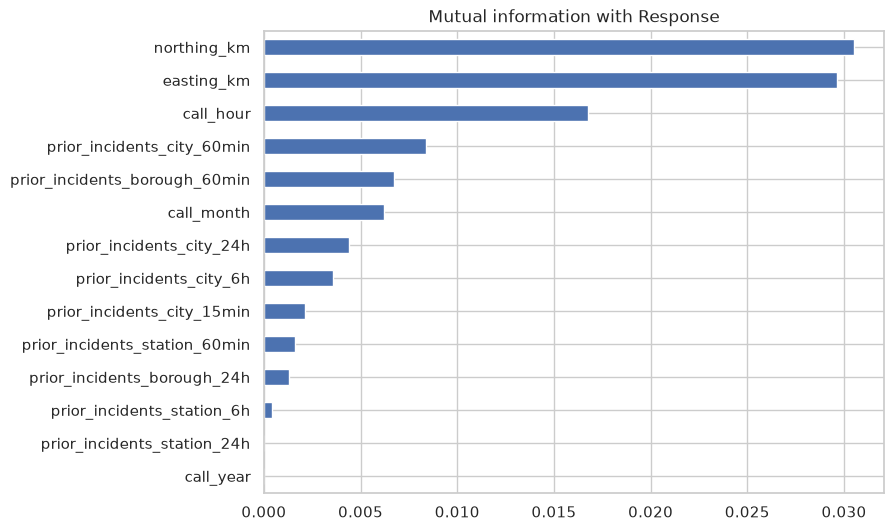

In [32]:
# Mutual information with the target: captures non-linear dependence that correlation misses
mutual_info = mutual_info_regression(train[numeric_columns], train[TARGET], random_state=RANDOM_SEED)
mutual_info_series = pd.Series(mutual_info, index=numeric_columns).sort_values()
mutual_info_series.plot.barh(figsize=(8, 6), title="Mutual information with Response")
save_figure("mutual_information")
plt.show()

## 8. Temporal structure

In [33]:
# Are rows ordered in time? Check whether call_year / call_month are monotone in row order.
print("call_year non-decreasing in row order:", train["call_year"].is_monotonic_increasing)
print("Rows per year:")
print(train["call_year"].value_counts().sort_index())
print("Train years:", sorted(train["call_year"].unique()), "| Test years:", sorted(test["call_year"].unique()))

call_year non-decreasing in row order: True
Rows per year:
call_year
2018    4737
2019    4753
2020    4432
2021    4924
2022    5154
Name: count, dtype: int64
Train years: [np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022)] | Test years: [np.int64(2022), np.int64(2023)]


## 9. Train versus test shift (features only)

In [34]:
# Compare numeric feature means/std between train and test
shift_table = pd.DataFrame({
    "train_mean": train[numeric_columns].mean(),
    "test_mean": test[numeric_columns].mean(),
    "train_std": train[numeric_columns].std(),
    "test_std": test[numeric_columns].std(),
})
shift_table["std_mean_diff"] = (shift_table["test_mean"] - shift_table["train_mean"]) / shift_table["train_std"]
display(shift_table.round(3))

,train_mean,test_mean,train_std,test_std,std_mean_diff
call_year,2020.042,2022.936,1.432,0.244,2.022
easting_km,530.600,530.713,9.707,9.660,0.012
northing_km,180.480,180.324,7.424,7.463,-0.021
prior_incidents_city_15min,3.687,4.186,2.734,2.483,0.182
prior_incidents_city_60min,14.672,16.686,8.262,6.715,0.244
prior_incidents_city_6h,82.734,95.307,35.727,31.101,0.352
prior_incidents_city_24h,304.679,354.628,65.220,51.466,0.766
prior_incidents_station_60min,0.212,0.217,0.793,0.486,0.006
prior_incidents_station_6h,1.051,1.181,1.685,1.312,0.077
prior_incidents_station_24h,3.737,4.294,3.522,3.062,0.158


In [35]:
# Adversarial validation: can a classifier tell train rows from test rows using features only?
# AUC near 0.5 => same distribution. AUC well above 0.5 => shift (then random validation may be optimistic).
adversarial_X = pd.concat([train[numeric_columns], test[numeric_columns]], axis=0)
adversarial_y = np.r_[np.zeros(len(train)), np.ones(len(test))]
adversarial_model = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_SEED)
auc_scores = cross_val_score(adversarial_model, adversarial_X, adversarial_y, cv=5, scoring="roc_auc")
print("Adversarial AUC per fold:", auc_scores.round(3), "| mean:", auc_scores.mean().round(3))

Adversarial AUC per fold: [0.984 1.    1.    1.    0.998] | mean: 0.996


In [ ]:
# Adversarial validation again, WITHOUT call_year: how much shift remains once the year is removed?
# call_year alone separates train (2018-2022) from test (2022-2023), so it hides any other drift.
columns_without_year = [column for column in numeric_columns if column != "call_year"]
adversarial_X_no_year = pd.concat([train[columns_without_year], test[columns_without_year]], axis=0)
adversarial_model_no_year = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_SEED)
auc_scores_no_year = cross_val_score(adversarial_model_no_year, adversarial_X_no_year, adversarial_y, cv=5, scoring="roc_auc")
print("Adversarial AUC per fold (no call_year):", auc_scores_no_year.round(3), "| mean:", auc_scores_no_year.mean().round(3))

# Which features still give train and test away?
adversarial_model_no_year.fit(adversarial_X_no_year, adversarial_y)
shift_importance = pd.Series(adversarial_model_no_year.feature_importances_, index=columns_without_year)
print(shift_importance.sort_values(ascending=False).round(3).head(6))


## 10. Baselines on a hold-out split (no test data)

In [36]:
# Hold-out split of the training data: 80% estimation, 20% validation
estimation, validation = train_test_split(train, test_size=0.2, random_state=RANDOM_SEED)
X_estimation, y_estimation = estimation[feature_columns], estimation[TARGET]
X_validation, y_validation = validation[feature_columns], validation[TARGET]

# Baseline 1: predict the estimation-set mean for everyone
mean_prediction = np.full(len(y_validation), y_estimation.mean())
print("Mean-predictor validation MSE:", round(mean_squared_error(y_validation, mean_prediction), 2))

# Baseline 2: 'kitchen-sink' OLS on all 18 features (categoricals one-hot encoded) = the assignment's lower benchmark
preprocessing = ColumnTransformer([
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
], remainder="passthrough")
ols_model = Pipeline([("prep", preprocessing), ("ols", LinearRegression())])
ols_model.fit(X_estimation, y_estimation)
ols_mse = mean_squared_error(y_validation, ols_model.predict(X_validation))
print("OLS validation MSE:", round(ols_mse, 2), "| RMSE:", round(ols_mse ** 0.5, 2))

Mean-predictor validation MSE: 16708.94
OLS validation MSE: 14777.63 | RMSE: 121.56


## 11. Findings and decisions
- **Target distribution / transformation:** `Response` is right-skewed (skew 1.43, kurtosis 4.90; mean 312 s, median 293 s, max 1203 s). A log transform is possible, but the metric is MSE on the raw scale, so any model trained on log(Response) must be back-transformed and checked on raw-scale validation MSE. Log needs care because of zeros (see outliers).
- **Outliers:** 4 rows have `Response` <= 0 (log gives divide-by-zero). The upper tail matters for MSE: the top 1% of rows carry 21.7% and the top 5% carry 46.2% of the total squared deviation. No missing values, duplicates, constant columns or impossible feature values (nested prior-incident windows are all consistent).
- **Encoding for `borough`, `postcode_district`, `station_ground`:** No unseen levels in test for any categorical. `borough` (33 levels, min 251 rows) and `station_ground` (102 levels, min 32 rows) have no rare levels, so one-hot or target encoding both work. `postcode_district` has 292 levels and 67 of them have < 30 rows, so it needs rare-level grouping or smoothed target encoding (fit inside CV folds). The three geography variables are not nested (130 postcodes and 79 stations span more than one borough). Borough means differ (std of borough means 26.9 s vs. within-borough std 132.1 s), so geography carries signal but explains little alone.
- **Multicollinearity among `prior_incidents_*`:** No pair of numeric features has |r| > 0.8, so OLS is not affected by severe pairwise collinearity. Ridge/lasso are still worth comparing since the windows are nested counts.
- **Train/test shift and validation strategy:** Train covers 2018-2022 and test covers 2022-2023 (`call_year` mean 2020.0 vs. 2022.9). Adversarial validation AUC is 0.996, driven almost entirely by the year. Without `call_year` it drops to 0.69 (folds 0.61-0.83, noisy because rows are time-ordered), so a smaller drift remains, mainly in `prior_incidents_city_24h` (higher in test: mean 355 vs. 305) and `call_month`. Location and hour contribute little. Rows are ordered by year. A random K-fold will be optimistic, so use a time-based hold-out (e.g. validate on 2022) alongside K-fold. Tree models cannot extrapolate `call_year` or the rising citywide counts to 2023, so consider dropping `call_year` and compare against a linear/ridge model.
- **Baseline MSEs to beat (random 80/20 hold-out):** mean predictor 16708.94; OLS 14777.63 (RMSE 121.56). These come from a random split, not a time-based one.
